In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

In [3]:
dataset, variances = load_data_and_var()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName',


In [4]:
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset, variances)

In [7]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

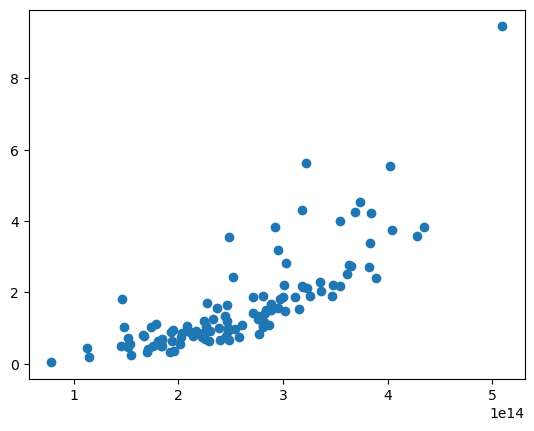

In [10]:
plt.scatter([nfw.M500 for nfw in nfws],[nfw.L500 for nfw in nfws])

In [11]:
test_nfw=nfws[0]

In [13]:
test_nfw.L500_numerical(1e-2, 1e-27)

(4.590334674151034, 42.050662980957206, 0.8371842483088942)

In [17]:
test_nfw.L500.value, test_nfw.L_err

(0.846881, 0.136706611275864)

In [39]:
p0=[-30, -2]
obs = [n.L500.value for n in nfws]

In [ ]:
import cProfile
import pstats

profiler = cProfile.Profile()
profiler.enable()

print(log_lik(p0, obs, nfws))

profiler.disable()
stats = pstats.Stats(profiler).sort_stats('cumtime')
stats.print_stats()

In [51]:
import numpy as np

# Create linearly spaced values from -40 to -30
s0_linear = np.linspace(-40, -27, 5)

# Create exponentially spaced values from -30 to -25
s0_exponential = -26 + np.geomspace(1, 3, 5) - 1

# Combine the arrays
s0_combined = np.concatenate((s0_linear, s0_exponential))

# Create the list of p0
p0_list = [[s0, -2] for s0 in s0_combined]

print(p0_list)

[[-40.0, -2], [-36.75, -2], [-33.5, -2], [-30.25, -2], [-27.0, -2], [-26.0, -2], [-25.68392598704751, -2], [-25.26794919243112, -2], [-24.720492943045222, -2], [-24.0, -2]]


In [52]:
log_liks = [log_lik(p, obs, nfws) for p in p0_list]

ValueError: f(a) and f(b) must have different signs

In [ ]:
plt.plot(p0_list, log_liks)